# Projeto — Assistente Inteligente de Vendas

Projeto de conclusão da trilha **Santander — Dados com Python e IA (DIO)**. O assistente
responde perguntas de negócio em português sobre uma base de vendas em SQLite, usando o que
foi construído nas aulas 04 a 07.

A pergunta de negócio: **como consultar vendas sem escrever SQL e sem abrir planilha?**

Duas camadas, de propósito:

1. **Roteamento por intenção** — pergunta reconhecida por palavra-chave vai direto para uma
   consulta parametrizada. Custo zero, resultado determinístico.
2. **Agente com ferramentas** — pergunta fora do roteiro vai para o `Agente` da aula 07, que
   só pode chamar ferramentas registradas (nunca SQL livre).

Sem chave de API, o provedor falso responde de forma determinística: o notebook roda em
qualquer clone e no CI.

## 1. Arquitetura

```
pergunta
   ├─ normalizar (minúsculas, sem acento)
   ├─ detectar_intencao ──► SQL parametrizado ──► resposta formatada
   └─ None ──► Agente ──► ferramenta whitelisted ──► validação ──► SQL
```

| Módulo | Papel |
|---|---|
| `assistente.py` | roteamento, consultas, ferramentas e `AssistenteVendas` |
| `llm.py` | `Provedor`, `Ferramenta`, `Agente`, `ProvedorFalso`, `ProvedorOpenAI` |
| `dados.py` | geração/limpeza da base e carga no SQLite |

Detalhes de decisão e trade-offs: `docs/PROJETO-ASSISTENTE-VENDAS.md`.

In [1]:
from __future__ import annotations

import sqlite3

import matplotlib.pyplot as plt
import pandas as pd

from opencode_harness import gerar_vendas, limpar_vendas
from opencode_harness.assistente import (
    AssistenteVendas,
    criar_banco,
    detectar_intencao,
    ferramentas_do_banco,
    receita_por_categoria,
    vendas_por_mes,
)
from opencode_harness.llm import (
    ChamadaFerramenta,
    Ferramenta,
    FerramentaDesconhecida,
    ProvedorFalso,
    ProvedorOpenAI,
    Resposta,
)

vendas = limpar_vendas(gerar_vendas(n=800, seed=42))
conn = criar_banco(vendas)
print("vendas no SQLite:", conn.execute("SELECT COUNT(*) FROM vendas").fetchone()[0])

vendas no SQLite: 797


## 2. Roteamento por intenção

Perguntas do dia a dia não deveriam custar token. O roteador reconhece o assunto e chama a
consulta certa; a resposta sai formatada em reais.

Repare que **a ordem das regras importa**: "receita por categoria" precisa cair em
`categoria`, não em `receita_total`.

In [2]:
assistente = AssistenteVendas(conn)

perguntas = [
    "Qual é a receita total?",
    "Receita por categoria",
    "Qual estado vende mais?",
    "Receita por canal",
    "Como foi a evolução mensal?",
    "Quais os produtos mais vendidos?",
    "Quantas vendas temos?",
    "Me dê um resumo",
]

for pergunta in perguntas:
    print("P:", pergunta)
    print("R:", assistente.perguntar(pergunta))
    print()

P: Qual é a receita total?
R: A receita total é R$ 884.347,97 em 797 vendas.

P: Receita por categoria
R: Receita por categoria: hardware: R$ 655.176,22; perifericos: R$ 119.540,22; software: R$ 62.578,31; educacao: R$ 47.053,22.

P: Qual estado vende mais?
R: Receita por UF: SP: R$ 325.062,17; MG: R$ 138.475,10; RJ: R$ 136.313,93; RS: R$ 121.184,99; BA: R$ 84.801,53; PR: R$ 62.086,77; NAO_INFORMADO: R$ 16.423,48.

P: Receita por canal
R: Receita por canal: online: R$ 538.845,57 (ticket médio R$ 1.060,72); loja: R$ 333.357,87 (ticket médio R$ 1.186,33); nao_informado: R$ 12.144,53 (ticket médio R$ 1.518,07).

P: Como foi a evolução mensal?
R: Melhor mês: 2026-12 com R$ 176.648,32; pior mês: 2026-10 com R$ 34.320,89. A base cobre 12 meses.

P: Quais os produtos mais vendidos?
R: Produtos mais vendidos: mouse (235 un.); teclado (227 un.); monitor (138 un.); notebook (137 un.); antivirus (137 un.).

P: Quantas vendas temos?
R: A base tem 797 vendas registradas.

P: Me dê um resumo
R: Resu

## 3. O roteador é uma tabela auditável

Cada linha abaixo mostra o que o roteador entendeu. Pergunta fora da lista vira `None` e
segue para o agente — não é erro, é o caminho alternativo.

In [3]:
exemplos = [
    "Quanto faturei no ano?",
    "Receita por UF",
    "Qual o ticket por canal?",
    "Quais os produtos mais vendidos?",
    "Quantas vendas temos?",
    "Quem é o melhor vendedor da equipe?",
]

pd.DataFrame(
    [(pergunta, detectar_intencao(pergunta) or "(agente)") for pergunta in exemplos],
    columns=["pergunta", "intencao"],
)

,pergunta,intencao
0,Quanto faturei no ano?,receita_total
1,Receita por UF,uf
2,Qual o ticket por canal?,canal
3,Quais os produtos mais vendidos?,produtos
4,Quantas vendas temos?,contagem
5,Quem é o melhor vendedor da equipe?,(agente)


## 4. Fallback por agente

Quando o roteador não reconhece, o agente entra. Com `ProvedorFalso`, ele responde o que sabe
fazer — sem inventar número. A segunda demo força o agente a **pedir uma ferramenta**, para
mostrar o loop completo: pergunta → ferramenta → resultado → resposta.

In [4]:
print(assistente.perguntar("Quem é o melhor vendedor da equipe?"))

Não encontrei essa informação na base. Posso falar sobre receita total, receita por categoria, UF ou canal, produtos mais vendidos, evolução mensal e quantidade de vendas.


In [5]:
provedor_com_ferramenta = ProvedorFalso(
    regras=[("me de um numero", Resposta(chamada=ChamadaFerramenta("receita_total")))]
)
assistente_ferramenta = AssistenteVendas(conn, provedor=provedor_com_ferramenta)

print(assistente_ferramenta.perguntar("me de um numero"))

Resultado: {"receita": 884347.97, "vendas": 797}


## 5. Segurança

O modelo escolhe **qual** ferramenta chamar, nunca **como** consultar o banco. Três barreiras
testáveis:

1. argumento fora do schema (ex.: `sql`) é recusado antes de executar;
2. ferramenta fora do registro lança `FerramentaDesconhecida`;
3. a conexão de `criar_banco` é somente leitura (`PRAGMA query_only`).

A célula prova as três sem derrubar o notebook.

In [6]:
ferramenta_produtos = next(
    item for item in ferramentas_do_banco(conn) if item.nome == "produtos_mais_vendidos"
)

try:
    ferramenta_produtos.executar({"limite": 2, "sql": "DROP TABLE vendas"})
except ValueError as erro:
    print("argumento bloqueado:", erro)

agente_malicioso = AssistenteVendas(
    conn,
    provedor=ProvedorFalso(regras=[("apague", Resposta(chamada=ChamadaFerramenta("apagar_tudo")))]),
)
try:
    agente_malicioso.perguntar("apague a base")
except FerramentaDesconhecida as erro:
    print("ferramenta bloqueada:", erro)

try:
    conn.execute("DELETE FROM vendas")
except sqlite3.OperationalError as erro:
    print("escrita bloqueada:", erro)

argumento bloqueado: argumentos inválidos para produtos_mais_vendidos: desconhecido: sql
ferramenta bloqueada: ferramenta 'apagar_tudo' não registrada
escrita bloqueada: attempt to write a readonly database


## 6. O dado por trás das respostas

As mesmas consultas que alimentam o assistente, abertas para inspeção. É isso que evita a
resposta "bonita" sem lastro.

In [7]:
categorias = pd.DataFrame(receita_por_categoria(conn))
categorias

,categoria,receita
0,hardware,655176.22
1,perifericos,119540.22
2,software,62578.31
3,educacao,47053.22


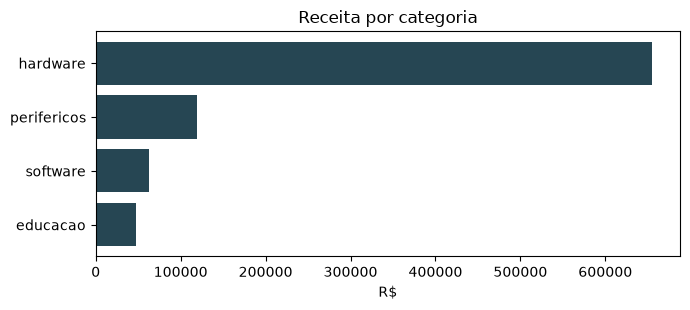

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(categorias["categoria"], categorias["receita"], color="#264653")
ax.invert_yaxis()
ax.set_title("Receita por categoria")
ax.set_xlabel("R$")
fig.tight_layout()
plt.show()
plt.close(fig)

In [9]:
mensal = pd.DataFrame(vendas_por_mes(conn))
mensal

,mes,receita,vendas
0,2026-01,48640.53,40
1,2026-02,47977.80,45
2,2026-03,78623.02,67
3,2026-04,124572.43,59
4,2026-05,41878.51,54
5,2026-06,73974.61,70
6,2026-07,84430.38,72
7,2026-08,40331.19,62
8,2026-09,64345.73,60
9,2026-10,34320.89,46


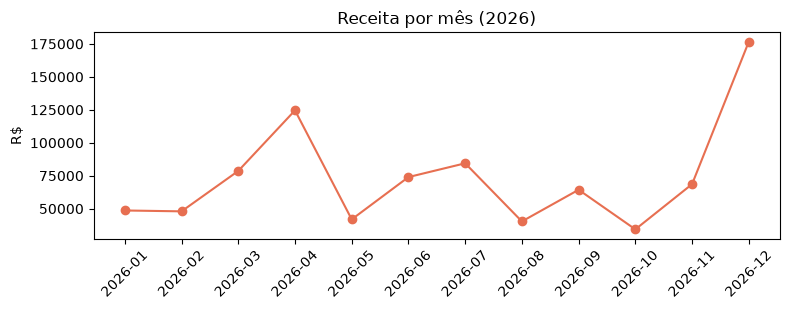

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(mensal["mes"], mensal["receita"], marker="o", color="#e76f51")
ax.set_title("Receita por mês (2026)")
ax.set_ylabel("R$")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()
plt.close(fig)

## 7. Provedor real (opcional)

Com `OPENAI_API_KEY`, a mesma pergunta vai para `https://api.openai.com/v1` — ou para o
endereço definido em `OPENAI_BASE_URL`. Sem chave, a célula apenas informa: o notebook
nunca depende de rede.

In [11]:
real = ProvedorOpenAI()
print("provedor real disponível:", real.disponivel)

if real.disponivel:
    assistente_real = AssistenteVendas(conn, provedor=real)
    print(assistente_real.perguntar("Quem é você e o que sabe responder?"))
else:
    print("Configure OPENAI_API_KEY para usar o provedor real.")

provedor real disponível: False
Configure OPENAI_API_KEY para usar o provedor real.


## 8. Conclusões

- O assistente resolve o caso comum **sem LLM**: mais barato, mais rápido e fácil de testar.
  O agente cobre a cauda, não o caminho principal.
- A separação `assistente.py` / `llm.py` deixa o projeto testável sem chave e sem rede —
  requisito para portfólio que qualquer pessoa consegue rodar.
- Whitelist + validação de argumento + SQL parametrizado são a diferença entre um agente útil
  e um risco de segurança.
- Resposta curta com o número usado é auditável: dá para conferir no banco em segundos.

## 9. Limitações e próximos passos

- A base é **sintética**; os números são didáticos.
- Não há memória entre perguntas; cada chamada é independente.
- Próximo passo natural: plugar o modelo da aula 06 e responder *"esta venda é de alto
  valor?"* com probabilidade, não só com regra.
- Expor como CLI ou API (FastAPI) e logar ferramenta chamada + argumentos para auditoria.

## 10. Entrega na DIO

- [x] Código no GitHub com testes e CI.
- [x] Notebook executado com saídas.
- [x] README do projeto explicando problema, dados e como rodar.
- [ ] Submissão no portal da DIO (exige login do aluno).
- [ ] Ajustar ao briefing oficial, se houver repositório de referência.

In [12]:
assert len(mensal) == 12
assert sum(item["receita"] for item in receita_por_categoria(conn)) > 0
assert detectar_intencao("Quem é o melhor vendedor da equipe?") is None
assert assistente.perguntar("Qual é a receita total?").startswith("A receita total é R$")
assert len(ferramentas_do_banco(conn)) == 7
print("assistente OK")

assistente OK
